<h1>Random Forest

Random forest é um algoritmo de aprendizado de máquina que utiliza múltiplas árvores de decisão para melhorar a precisão e evitar o overfitting. 
Ele funciona criando várias árvores de decisão a partir de amostras aleatórias dos dados e, em seguida, combina as previsões dessas árvores para obter uma previsão final mais robusta.

<h2>Versão 1

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

In [3]:

data = pd.read_csv("C:/projetos/GitHub/IA_Aulas/A.Basicos/A.A.datasets/insurance.csv", keep_default_na=False)
data = data.drop(columns=['Unnamed: 0'], index=1)

X = data.drop(columns=["Accident"]).values

y = data["Accident"].values

#print(X)
#print(y)


In [4]:
labelencoder = LabelEncoder()
for i in range(X.shape[1]):
    if X[:,i].dtype == 'object':
        X[:, i] = labelencoder.fit_transform(X[:, i])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=12)

modelo = RandomForestClassifier(random_state=1, max_depth=20, max_leaf_nodes=12, n_estimators=500) # essa parte é bem parecida com arvore de decisão
modelo.fit(X_train, y_train)                                                                       # n_estimators define a quantidade de arvores que vão ser "treinadas" 


tree_index = 0
tree_to_visualise = modelo.estimators_[tree_index]

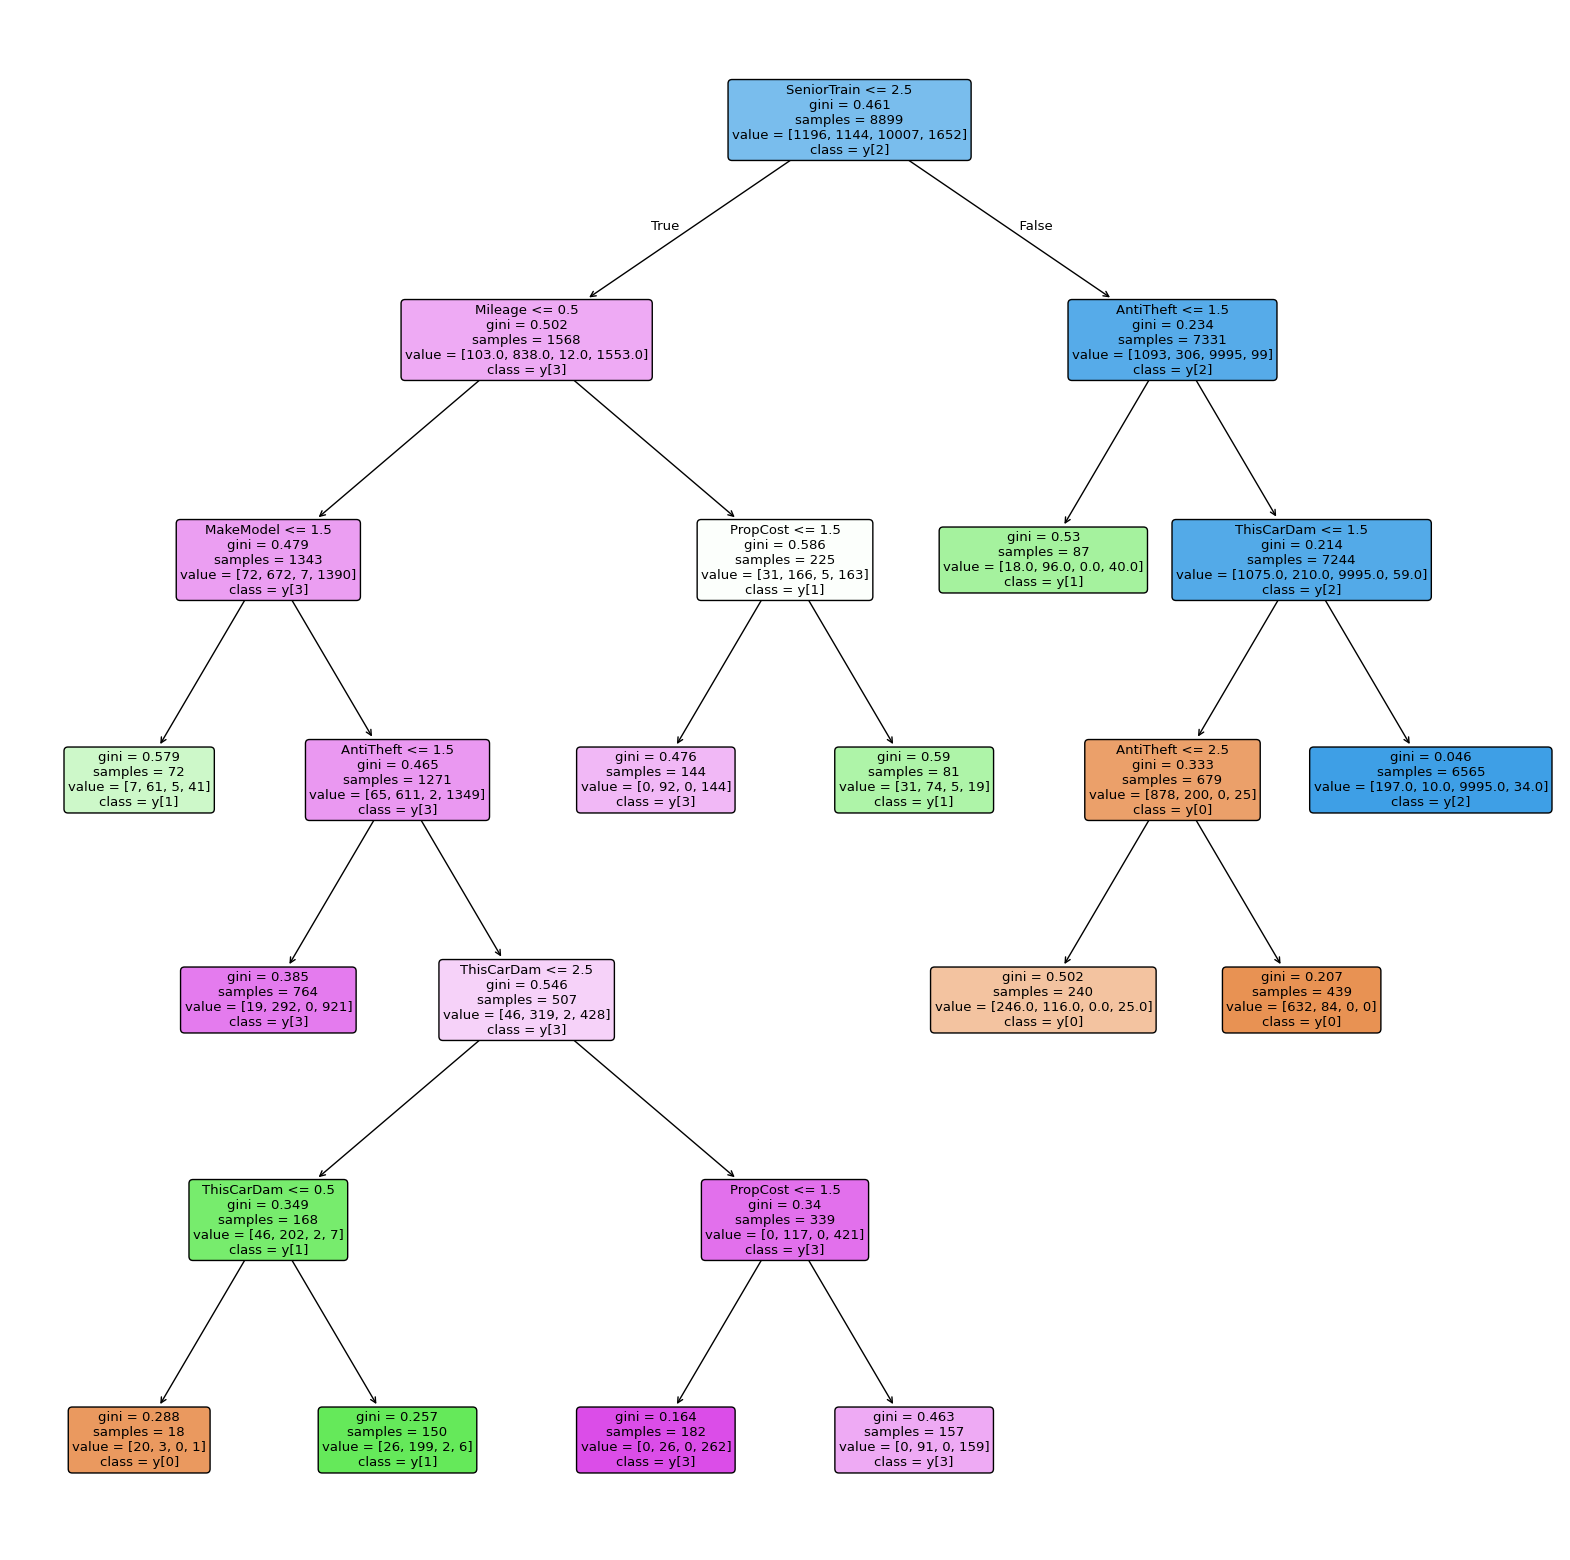

0.9351666666666667
0.9332185772604121
0.9351666666666667
0.9311932466665762

              precision    recall  f1-score   support

        Mild       0.90      0.60      0.72       527
    Moderate       0.77      0.73      0.75       483
        None       0.96      1.00      0.98      4295
      Severe       0.88      0.93      0.90       695

    accuracy                           0.94      6000
   macro avg       0.88      0.82      0.84      6000
weighted avg       0.93      0.94      0.93      6000



In [5]:
plt.figure(figsize=(20,20))
plot_tree(tree_to_visualise, filled=True, feature_names= data.columns[:-1], class_names=True, rounded=True)
plt.show()

previsao = modelo.predict(X_test)
print(accuracy_score(y_test, previsao))
print(precision_score(y_test, previsao, average="weighted"))
print(recall_score(y_test, previsao, average="weighted"))
print(f1_score(y_test, previsao, average="weighted"))
print()
print(classification_report(y_test, previsao))

<h2> Versão 2

In [6]:
X2= data.drop(columns=["Accident"]).values
y2 = data["Accident"].values

In [7]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.3, random_state=12)

for i in range(X_train2.shape[1]):
    if X_train2[:,i].dtype == 'object':
        labelencoder = LabelEncoder()
        X_train2[:, i] = labelencoder.fit_transform(X_train2[:, i])
        X_test2[:, i] = labelencoder.fit_transform(X_test2[:, i])


modelo2 = RandomForestClassifier(random_state=1, max_depth=20, max_leaf_nodes=12, n_estimators=500)
modelo2.fit(X_train2, y_train2) 

tree_index2 = 0
tree_to_visualise2 = modelo.estimators_[tree_index2]

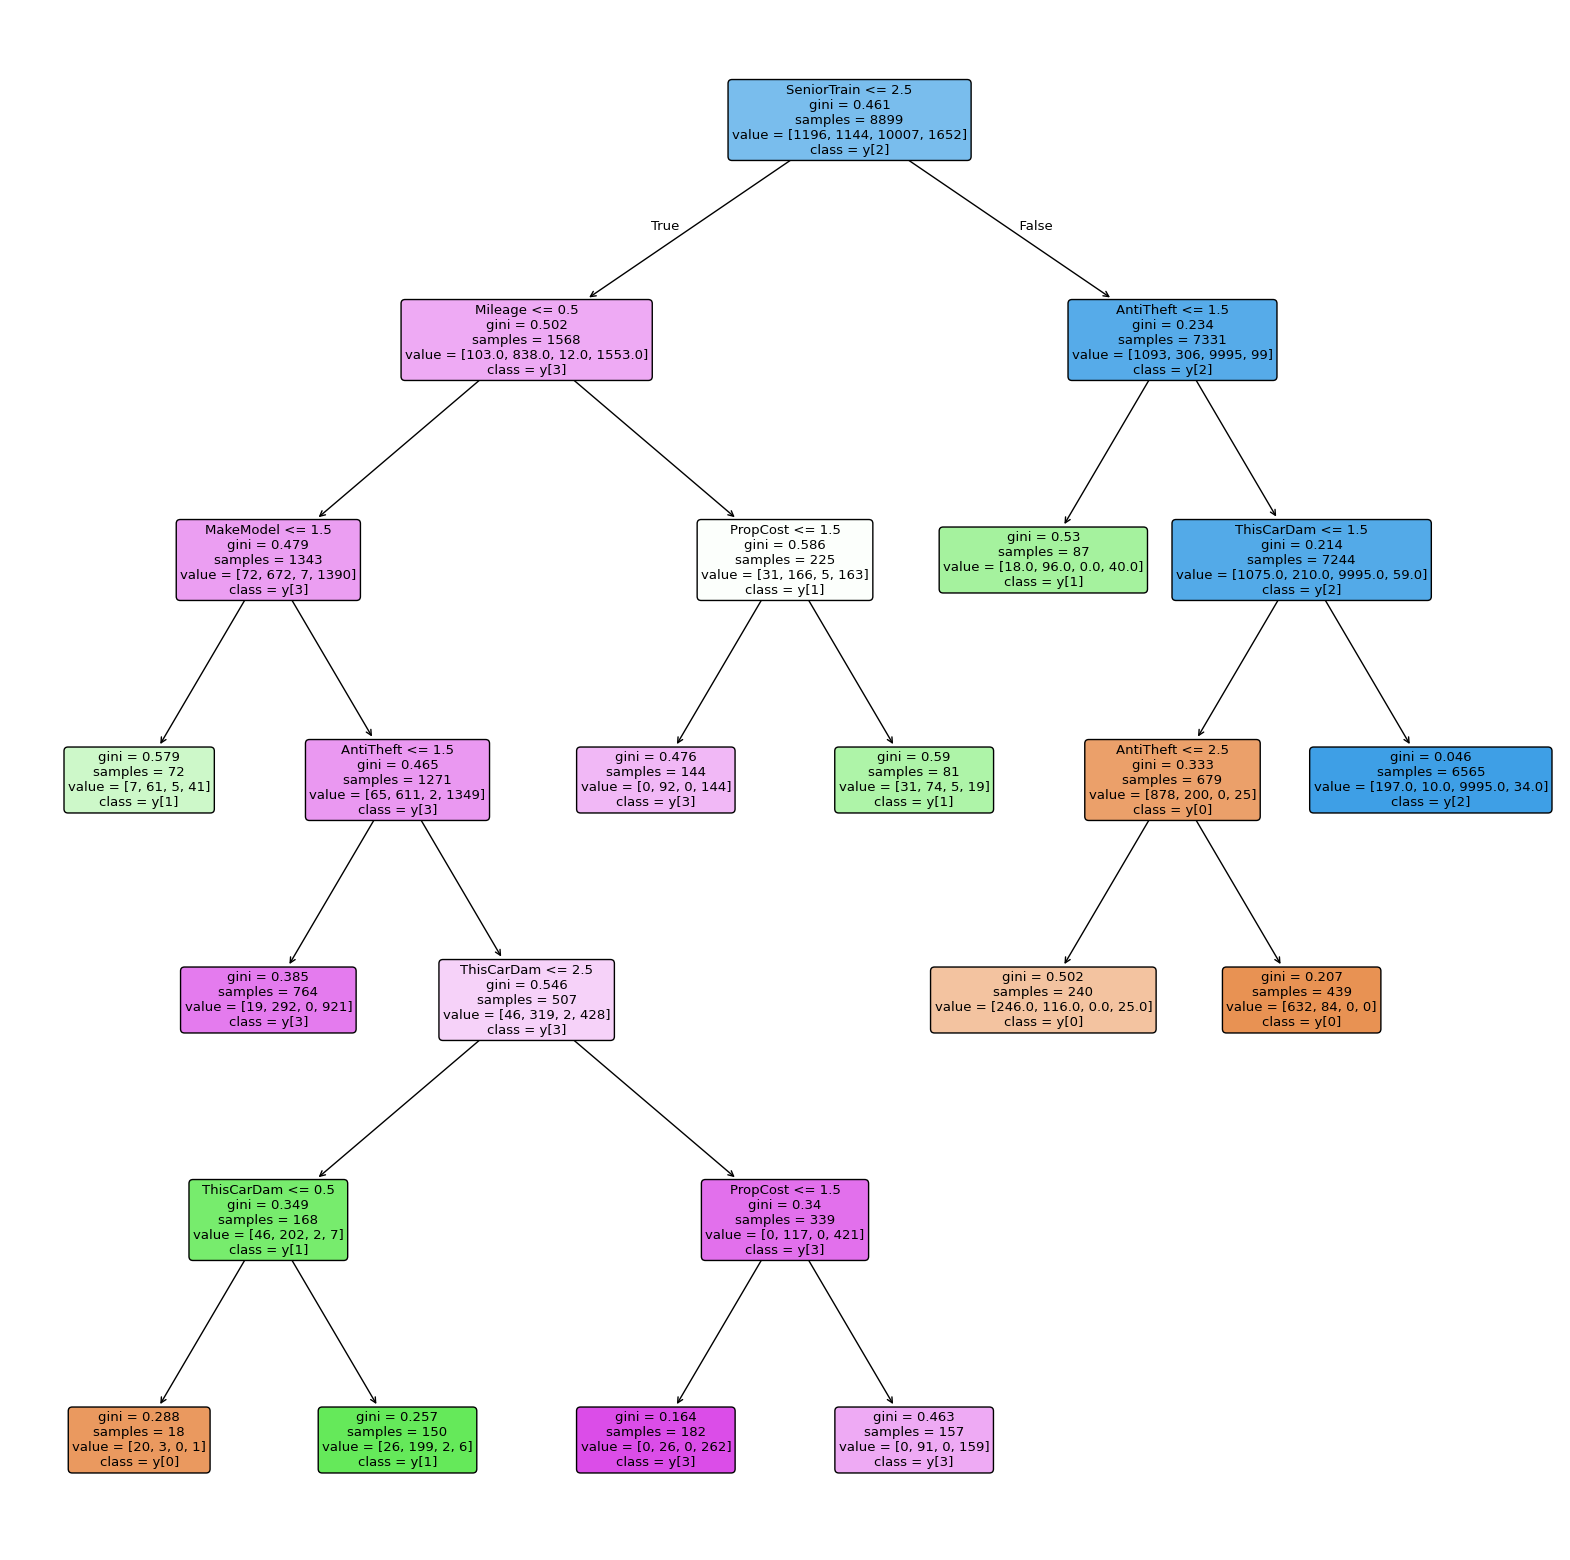

0.9351666666666667
0.9332185772604121
0.9351666666666667
0.9311932466665762

              precision    recall  f1-score   support

        Mild       0.90      0.60      0.72       527
    Moderate       0.77      0.73      0.75       483
        None       0.96      1.00      0.98      4295
      Severe       0.88      0.93      0.90       695

    accuracy                           0.94      6000
   macro avg       0.88      0.82      0.84      6000
weighted avg       0.93      0.94      0.93      6000



In [8]:
plt.figure(figsize=(20,20))
plot_tree(tree_to_visualise2, filled=True, feature_names= data.columns[:-1], class_names=True, rounded=True)
plt.show()

previsao2 = modelo.predict(X_test2)
print(accuracy_score(y_test2, previsao2))
print(precision_score(y_test2, previsao2, average="weighted"))
print(recall_score(y_test2, previsao2, average="weighted"))
print(f1_score(y_test2, previsao2, average="weighted"))
print()
print(classification_report(y_test2, previsao2))